# From artifacts to the dashboard

Follow the publication pointer into the FastAPI endpoints and React pages.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

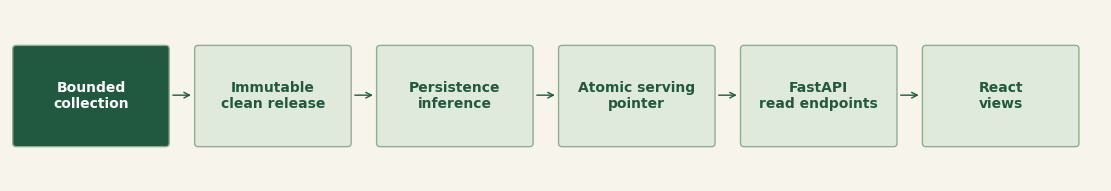

,Local publication
Release,1c2d2f62254a6d3e
Batch target,2026-11-13
Issue,2026-11-13T21:28:46.252788+05:30
Views,"coverage, last_success, quality, status, strat..."


,Page,Read endpoint,Role
0,Markets,/api/v4/market-map,Reports and market references
1,Warehouses,/api/v4/warehouses,Storage capacity and compatibility
2,Strategies,/api/v4/strategies?plan=true,Ranked trades and timing options


In [2]:
diagram(["Bounded\ncollection", "Immutable\nclean release", "Persistence\ninference", "Atomic serving\npointer", "FastAPI\nread endpoints", "React\nviews"])
snap = publication()
display(pd.Series({"Release":snap["release"]["release"],"Batch target":snap["batch"]["target_date"],
                   "Issue":snap["batch"]["issue"],"Views":", ".join(sorted(snap["auxiliary"]))}).to_frame("Local publication"))
display(pd.DataFrame([
    ["Markets","/api/v4/market-map","Reports and market references"],
    ["Warehouses","/api/v4/warehouses","Storage capacity and compatibility"],
    ["Strategies","/api/v4/strategies?plan=true","Ranked trades and timing options"],
],columns=["Page","Read endpoint","Role"]))

In [3]:
from urllib.request import urlopen
from urllib.error import URLError

try:
    with urlopen("http://127.0.0.1:8000/api/v3/daily/metadata", timeout=2) as response:
        metadata = json.load(response)
    print("Local API response")
    display(pd.Series({k: metadata[k] for k in ("dataset_version","batch_target_date","model")}).to_frame())
except (URLError, TimeoutError, OSError):
    print("Local API unavailable. Using the saved publication above.")

Local API response


,0
dataset_version,daily-prices-v1:1c2d2f62254a6d3e
batch_target_date,2026-11-13
model,persistence


The network example is a read-only request to localhost. Opening the notebook and inspecting the publication require no running server.

**Takeaway** · One completed publication binds the dataset, forecast batch and derived views.

**Next** · Summarize research and application outcomes in Notebook 14.